# Regime-Shift Handling: Hard Cutover vs. Recency-Weighted Training
> **Companion to notebook 01.** Ukraine's official alert reporting shifted from
> oblast-wide blanket alerts to localized raion/hromada alerts over
> Aug-Nov 2025 (see notebook 01, section 2.1b). That's not just a data gap -
> it's a change in what "an alert episode" structurally looks like, which
> changes the duration/gap distributions a model should learn.
>
> This notebook compares two ways to handle it, training the **same model
> classes** on **the same data pool**, evaluated on **the same held-out
> recent test window**, so the only thing that differs is the data strategy:
>
> 1. **Hard cutover** - train only on data from after the regime boundary.
> 2. **Recency-weighted** - train on the full history, down-weighting older
>    (pre-shift) episodes exponentially so the fit still leans toward
>    current behavior.
>
> *Disclaimer: statistical experiment for research and analysis. Decides
> nothing about the app by itself - see the verdict cell at the end.*


## 1. Setup & Imports


In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(project_root / "src"))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from alertpred.config import MODELS_DIR
from alertpred.data.build_dataset import build_master_alerts_dataset
from alertpred.features.builder import sample_as_of_alert_moments, sample_as_of_gap_moments
from alertpred.models.baseline import EmpiricalConditionalBaseline
from alertpred.models.quantile_lgbm import LightGBMQuantileModel
from alertpred.evaluation.metrics import evaluate_quantile_predictions

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11

print(f"Project root: {project_root}")


Project root: /Users/allakovalcuk/Agentic_AI


## 2. Load the Master Dataset
Reuses the exact pipeline walked through step-by-step in notebook 01
(`alertpred.data.build_dataset.build_master_alerts_dataset`): raw CSV ->
bias-corrected oblast rollup -> alerts.in.ua backfill (if a token is
configured) -> merge. See notebook 01 for the detailed walkthrough and
validation of each step; this notebook starts from its result.


In [2]:
df_alerts, df_gaps = build_master_alerts_dataset(use_api_backfill=True)
print(f"Alert episodes: {len(df_alerts):,}  |  Gap episodes: {len(df_gaps):,}")
print(f"Date range: {df_alerts['started_at'].min().strftime('%Y-%m-%d')} to {df_alerts['started_at'].max().strftime('%Y-%m-%d')}")
display(df_alerts['level'].value_counts().rename('episodes'))


  [1/27] khmelnytskyi (uid=3): 107 completed episodes
  [2/27] vinnytsia (uid=4): 146 completed episodes


  [3/27] rivne (uid=5): 128 completed episodes
  [4/27] volyn (uid=8): 67 completed episodes


  [5/27] dnipropetrovsk (uid=9): 42 completed episodes (3 dropped, >72h merged chain)
  [6/27] zhytomyr (uid=10): 231 completed episodes
  [7/27] zakarpattia (uid=11): 3 completed episodes


  [8/27] zaporizhzhia (uid=12): 159 completed episodes
  [9/27] ivano_frankivsk (uid=13): 16 completed episodes


  [10/27] kyiv (uid=14): 241 completed episodes


...

  [20/27] cherkasy (uid=24): 229 completed episodes


  [21/27] chernihiv (uid=25): 189 completed episodes
  [22/27] chernivtsi (uid=26): 34 completed episodes
  [23/27] lviv (uid=27): 18 completed episodes
  [24/27] donetsk (uid=28): 59 completed episodes
  [25/27] crimea (uid=29): 0 completed episodes
  [26/27] sevastopol (uid=30): 0 completed episodes


  [27/27] kyiv_city (uid=31): 218 completed episodes


Filling 4 days 21:41:48.292000 gap (2026-09-07 to 2026-09-12) with 578 volunteer-sourced episodes
Alert episodes: 90,061  |  Gap episodes: 90,030
Date range: 2022-03-15 to 2026-10-12


level
oblast              56648
oblast_rollup       32835
oblast_volunteer      578
Name: episodes, dtype: int64

## 3. Identify the Regime Boundary
Compute the monthly share of episodes that required a rollup (i.e. were
*not* native oblast-wide alerts) and pick the first month where that share
crosses 50% and stays there - that's where "oblast-wide" stopped being the
typical way an alert looked.


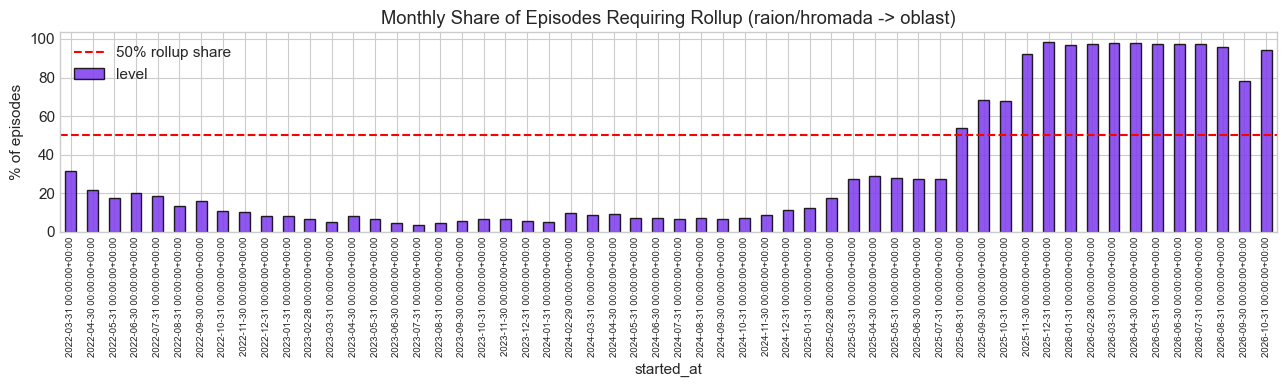

Regime boundary (start of raion-dominant era): 2025-08-01


In [3]:
monthly = df_alerts.set_index('started_at').resample('ME')['level'].apply(
    lambda s: (s == 'oblast_rollup').mean() * 100
)

plt.figure(figsize=(13, 4))
monthly.plot(kind='bar', color='#7c3aed', edgecolor='black', alpha=0.85)
plt.axhline(50, color='red', linestyle='--', label='50% rollup share')
plt.title("Monthly Share of Episodes Requiring Rollup (raion/hromada -> oblast)")
plt.ylabel("% of episodes")
plt.xticks(rotation=90, fontsize=7)
plt.legend()
plt.tight_layout()
plt.show()

# First month where rollup share crosses 50% and never drops back below it
above_50 = monthly >= 50.0
regime_b_start_ts = above_50[above_50[::-1].cummin()[::-1]].index.min()
REGIME_CUTOVER = regime_b_start_ts.tz_convert('UTC').replace(day=1, hour=0, minute=0, second=0, microsecond=0)
print(f"Regime boundary (start of raion-dominant era): {REGIME_CUTOVER.strftime('%Y-%m-%d')}")


## 4. Two Training Strategies, One Shared Test Window
Both strategies draw from the same trainable pool (everything before the
test window - no strategy gets to see data the other couldn't). The test
window is the most recent slice, held out from both: that's what the app
actually needs to be accurate on *right now*, regardless of how a model
was trained.

**Recency weight** (strategy 2): `0.5 ** (age_days / HALF_LIFE_DAYS)` - an
episode HALF_LIFE_DAYS old counts half as much as a fresh one. 60 days is
a starting point (roughly "the current regime's own age" at the time of
writing) - re-tune once more regime-B history accumulates.


In [4]:
TEST_WINDOW_DAYS = 21
HALF_LIFE_DAYS = 60

test_cutoff = df_alerts['started_at'].max() - pd.Timedelta(days=TEST_WINDOW_DAYS)
df_test_raw = df_alerts[df_alerts['started_at'] >= test_cutoff].copy()
df_trainable = df_alerts[df_alerts['started_at'] < test_cutoff].copy()

# Strategy 1: hard cutover
df_train_cutover = df_trainable[df_trainable['started_at'] >= REGIME_CUTOVER].copy()

# Strategy 2: full history, recency-weighted
df_train_weighted = df_trainable.copy()
age_days = (test_cutoff - df_train_weighted['started_at']).dt.total_seconds() / 86400.0
df_train_weighted['recency_weight'] = 0.5 ** (age_days / HALF_LIFE_DAYS)

print(f"Test window        : {test_cutoff.strftime('%Y-%m-%d')} to {df_alerts['started_at'].max().strftime('%Y-%m-%d')} ({len(df_test_raw):,} episodes)")
print(f"Cutover training    : {len(df_train_cutover):,} episodes (from {REGIME_CUTOVER.strftime('%Y-%m-%d')})")
print(f"Weighted training    : {len(df_train_weighted):,} episodes (full history, weight range {df_train_weighted['recency_weight'].min():.4f}-{df_train_weighted['recency_weight'].max():.3f})")


Test window        : 2026-09-21 to 2026-10-12 (2,835 episodes)
Cutover training    : 25,438 episodes (from 2025-08-01)
Weighted training    : 87,226 episodes (full history, weight range 0.0000-1.000)


## 5. Task A As-Of Samples
Same point-in-time sampling as notebook 01 (`sample_as_of_alert_moments`).
The recency weight is attached back onto the weighted-strategy samples by
joining on `(region_id, start_ts)`, since the sampler doesn't carry
arbitrary extra columns through on its own.


In [5]:
test_a = sample_as_of_alert_moments(df_test_raw)
train_a_cutover = sample_as_of_alert_moments(df_train_cutover)

train_a_weighted = sample_as_of_alert_moments(df_train_weighted)
weight_lookup = df_train_weighted[['region_id', 'started_at', 'recency_weight']].rename(columns={'started_at': 'start_ts'})
train_a_weighted = train_a_weighted.merge(weight_lookup, on=['region_id', 'start_ts'], how='left')

print(f"Test samples: {len(test_a):,}")
print(f"Cutover train samples: {len(train_a_cutover):,}")
print(f"Weighted train samples: {len(train_a_weighted):,} (weight nulls: {train_a_weighted['recency_weight'].isna().sum()})")


Test samples: 18,990
Cutover train samples: 178,520
Weighted train samples: 598,452 (weight nulls: 0)


## 6. Baseline Empirical Comparison (Task A)
The empirical conditional baseline (PLAN.md 5.1) is cheap enough to be a
fair, variance-free comparison of the two *data* strategies before
introducing a more complex model.


In [6]:
results = []

baseline_cutover = EmpiricalConditionalBaseline().fit(df_train_cutover)
pred_cutover = baseline_cutover.predict_batch(test_a, elapsed_col='elapsed_min')
m = evaluate_quantile_predictions(
    test_a['target_remaining_min'].values,
    pred_cutover['baseline_p10'].values, pred_cutover['baseline_p50'].values, pred_cutover['baseline_p90'].values,
)
results.append({'task': 'A', 'model': 'Empirical Baseline', 'strategy': 'Hard Cutover', **m})

baseline_weighted = EmpiricalConditionalBaseline().fit(df_train_weighted, weight_col='recency_weight')
pred_weighted = baseline_weighted.predict_batch(test_a, elapsed_col='elapsed_min')
m = evaluate_quantile_predictions(
    test_a['target_remaining_min'].values,
    pred_weighted['baseline_p10'].values, pred_weighted['baseline_p50'].values, pred_weighted['baseline_p90'].values,
)
results.append({'task': 'A', 'model': 'Empirical Baseline', 'strategy': 'Recency-Weighted', **m})

display(pd.DataFrame(results).set_index(['task', 'model', 'strategy']).round(2))


mae_p50_min  median_ae_p50_min  \
task model              strategy                                           
A    Empirical Baseline Hard Cutover            86.25              33.01   
                        Recency-Weighted        85.56              31.01   

                                          pinball_loss_p10  pinball_loss_p50  \
task model              strategy                                               
A    Empirical Baseline Hard Cutover                 10.56             43.12   
                        Recency-Weighted             10.54             42.78   

                                          pinball_loss_p90  mean_pinball_loss  \
task model              strategy                                                
A    Empirical Baseline Hard Cutover                 36.52              30.07   
                        Recency-Weighted             35.36              29.56   

                                          coverage_p10_p90  
task model              strategy                            
A    Empirical Baseline Hard Cutover                  0.81  
                        Recency-Weighted              0.80

## 7. LightGBM Quantile Comparison (Task A)
Same two data strategies, now with a model that can actually use
`sample_weight` (vs. the baseline's weighted-percentile trick) and
region/time features beyond just elapsed time.


In [7]:
lgbm_feature_cols = ['region_id', 'elapsed_min', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'is_weekend', 'month']

lgbm_cutover = LightGBMQuantileModel(feature_cols=lgbm_feature_cols)
lgbm_cutover.fit(train_a_cutover, target_col='target_remaining_min')
pred = lgbm_cutover.predict(test_a)
m = evaluate_quantile_predictions(test_a['target_remaining_min'].values, pred['pred_p10'].values, pred['pred_p50'].values, pred['pred_p90'].values)
results.append({'task': 'A', 'model': 'LightGBM Quantile', 'strategy': 'Hard Cutover', **m})

lgbm_weighted = LightGBMQuantileModel(feature_cols=lgbm_feature_cols)
lgbm_weighted.fit(train_a_weighted, target_col='target_remaining_min', weight_col='recency_weight')
pred = lgbm_weighted.predict(test_a)
m = evaluate_quantile_predictions(test_a['target_remaining_min'].values, pred['pred_p10'].values, pred['pred_p50'].values, pred['pred_p90'].values)
results.append({'task': 'A', 'model': 'LightGBM Quantile', 'strategy': 'Recency-Weighted', **m})

display(pd.DataFrame(results).set_index(['task', 'model', 'strategy']).round(2))


mae_p50_min  median_ae_p50_min  \
task model              strategy                                           
A    Empirical Baseline Hard Cutover            86.25              33.01   
                        Recency-Weighted        85.56              31.01   
     LightGBM Quantile  Hard Cutover            85.68              34.94   
                        Recency-Weighted        84.92              32.35   

                                          pinball_loss_p10  pinball_loss_p50  \
task model              strategy                                               
A    Empirical Baseline Hard Cutover                 10.56             43.12   
                        Recency-Weighted             10.54             42.78   
     LightGBM Quantile  Hard Cutover                 10.58             42.84   
                        Recency-Weighted             10.51             42.46   

                                          pinball_loss_p90  mean_pinball_loss  \
task model              strategy                                                
A    Empirical Baseline Hard Cutover                 36.52              30.07   
                        Recency-Weighted             35.36              29.56   
     LightGBM Quantile  Hard Cutover                 37.09              30.17   
                        Recency-Weighted             37.32              30.10   

                                          coverage_p10_p90  
task model              strategy                            
A    Empirical Baseline Hard Cutover                  0.81  
                        Recency-Weighted              0.80  
     LightGBM Quantile  Hard Cutover                  0.77  
                        Recency-Weighted              0.78

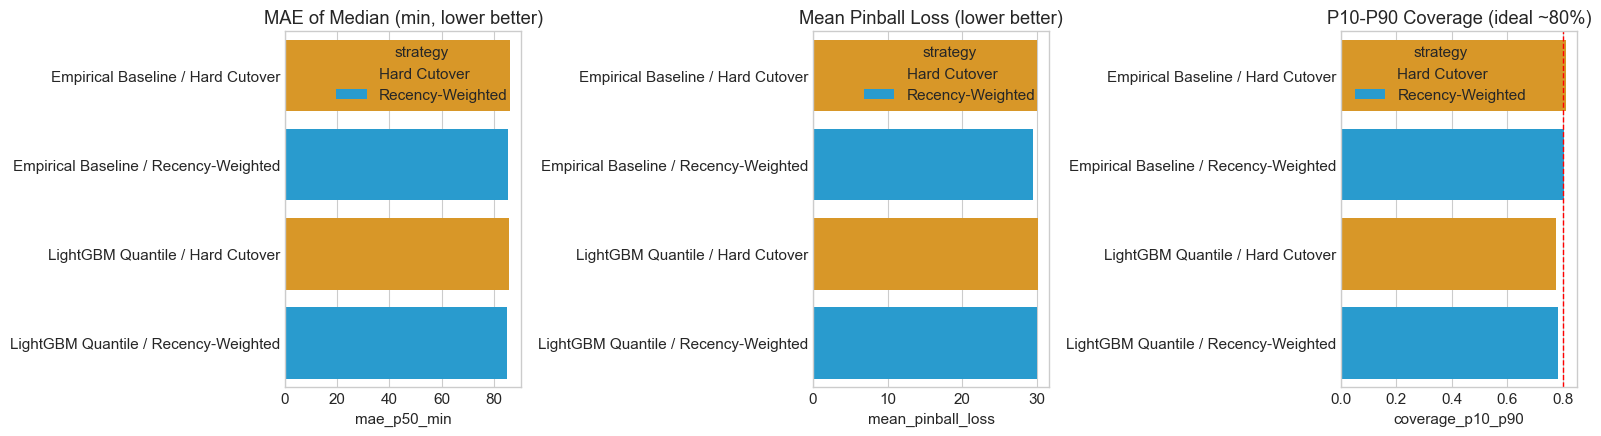

In [8]:
# Visual comparison: MAE and pinball loss, all four Task A variants
df_res_a = pd.DataFrame([r for r in results if r['task'] == 'A'])
df_res_a['label'] = df_res_a['model'] + ' / ' + df_res_a['strategy']

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, metric, title in zip(
    axes,
    ['mae_p50_min', 'mean_pinball_loss', 'coverage_p10_p90'],
    ['MAE of Median (min, lower better)', 'Mean Pinball Loss (lower better)', 'P10-P90 Coverage (ideal ~80%)'],
):
    sns.barplot(data=df_res_a, y='label', x=metric, hue='strategy', ax=ax, dodge=False, palette=['#f59e0b', '#0ea5e9'])
    ax.set_title(title)
    ax.set_ylabel('')
    if metric == 'coverage_p10_p90':
        ax.axvline(0.80, color='red', linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()


## 8. Task B (Time to Next Alert): Baseline Comparison
Same two-strategy comparison for the quiet-gap task. The LightGBM version
would follow an identical pattern to section 7 (target column
`target_remaining_gap_min`, `elapsed_quiet_min` in place of `elapsed_min`)
- omitted here for brevity since section 7 already demonstrates it.


In [9]:
gaps_test_raw = df_gaps[df_gaps['gap_start'] >= test_cutoff].copy()
gaps_trainable = df_gaps[df_gaps['gap_start'] < test_cutoff].copy()
gaps_train_cutover = gaps_trainable[gaps_trainable['gap_start'] >= REGIME_CUTOVER].copy()

gaps_train_weighted = gaps_trainable.copy()
gap_age_days = (test_cutoff - gaps_train_weighted['gap_start']).dt.total_seconds() / 86400.0
gaps_train_weighted['recency_weight'] = 0.5 ** (gap_age_days / HALF_LIFE_DAYS)

test_b = sample_as_of_gap_moments(gaps_test_raw)
train_b_cutover = sample_as_of_gap_moments(gaps_train_cutover)

train_b_weighted = sample_as_of_gap_moments(gaps_train_weighted)
weight_lookup_b = gaps_train_weighted[['region_id', 'gap_start', 'recency_weight']].rename(columns={'gap_start': 'gap_start_ts'})
train_b_weighted = train_b_weighted.merge(weight_lookup_b, on=['region_id', 'gap_start_ts'], how='left')

print(f"Test samples: {len(test_b):,}  |  Cutover train: {len(train_b_cutover):,}  |  Weighted train: {len(train_b_weighted):,}")


Test samples: 6,707  |  Cutover train: 84,550  |  Weighted train: 350,561


In [10]:
baseline_b_cutover = EmpiricalConditionalBaseline().fit(gaps_train_cutover, duration_col='gap_duration_min')
pred_b = baseline_b_cutover.predict_batch(test_b, elapsed_col='elapsed_quiet_min')
m = evaluate_quantile_predictions(test_b['target_remaining_gap_min'].values, pred_b['baseline_p10'].values, pred_b['baseline_p50'].values, pred_b['baseline_p90'].values)
results.append({'task': 'B', 'model': 'Empirical Baseline', 'strategy': 'Hard Cutover', **m})

baseline_b_weighted = EmpiricalConditionalBaseline().fit(gaps_train_weighted, duration_col='gap_duration_min', weight_col='recency_weight')
pred_b = baseline_b_weighted.predict_batch(test_b, elapsed_col='elapsed_quiet_min')
m = evaluate_quantile_predictions(test_b['target_remaining_gap_min'].values, pred_b['baseline_p10'].values, pred_b['baseline_p50'].values, pred_b['baseline_p90'].values)
results.append({'task': 'B', 'model': 'Empirical Baseline', 'strategy': 'Recency-Weighted', **m})

display(pd.DataFrame([r for r in results if r['task'] == 'B']).set_index(['task', 'model', 'strategy']).round(2))


mae_p50_min  median_ae_p50_min  \
task model              strategy                                           
B    Empirical Baseline Hard Cutover           422.00             155.53   
                        Recency-Weighted       310.65              93.61   

                                          pinball_loss_p10  pinball_loss_p50  \
task model              strategy                                               
B    Empirical Baseline Hard Cutover                 29.09            211.00   
                        Recency-Weighted             28.40            155.33   

                                          pinball_loss_p90  mean_pinball_loss  \
task model              strategy                                                
B    Empirical Baseline Hard Cutover                242.84             160.98   
                        Recency-Weighted            198.45             127.39   

                                          coverage_p10_p90  
task model              strategy                            
B    Empirical Baseline Hard Cutover                  0.72  
                        Recency-Weighted              0.76

## 9. Verdict
Data-driven summary across every (task, model) pair of which strategy won
on MAE and on pinball loss - a recommendation to weigh, not a decision
already made. This notebook changes nothing in `train.py` or the app by
itself; that's a deliberate next step once you've looked at the numbers
above and agree with (or override) the summary below.


In [11]:
df_all = pd.DataFrame(results)
wins = []
for (task, model), grp in df_all.groupby(['task', 'model']):
    mae_winner = grp.loc[grp['mae_p50_min'].idxmin(), 'strategy']
    pinball_winner = grp.loc[grp['mean_pinball_loss'].idxmin(), 'strategy']
    wins.append({'task': task, 'model': model, 'lower_mae': mae_winner, 'lower_pinball_loss': pinball_winner})

df_wins = pd.DataFrame(wins)
display(df_wins)

from collections import Counter
tally = Counter(df_wins['lower_mae']) + Counter(df_wins['lower_pinball_loss'])
print("\nWin tally across all (task, model, metric) comparisons:")
for strategy, count in tally.most_common():
    print(f"  {strategy}: {count}")
print("\nThis is a starting signal, not a final call - re-run this notebook as more")
print("regime-B history accumulates (via the app's own poller) and the comparison")
print("will become more statistically reliable.")


,task,model,lower_mae,lower_pinball_loss
0,A,Empirical Baseline,Recency-Weighted,Recency-Weighted
1,A,LightGBM Quantile,Recency-Weighted,Recency-Weighted
2,B,Empirical Baseline,Recency-Weighted,Recency-Weighted



Win tally across all (task, model, metric) comparisons:
  Recency-Weighted: 6

This is a starting signal, not a final call - re-run this notebook as more
regime-B history accumulates (via the app's own poller) and the comparison
will become more statistically reliable.
